In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
import matplotlib.ticker as mtick

modelling_folder = os.environ["MODELLING_FOLDER"]

def plot_feature_importance(configs, epoch, mask_value, mask_before_normalization, normalise, bands, config_names=None, only_three=False):

   if isinstance(configs, str):
      configs = [configs]
   if not config_names:
      config_names = configs
   fig, axes = plt.subplots(nrows=1, ncols=len(configs), figsize=(7*len(configs) if len(configs) > 1 else 8, 15 if bands else 5), sharey=True)
   
   for i, config in enumerate(configs):

      ax = axes[i] if len(configs) != 1 else axes
      data = pd.read_csv(f"{modelling_folder}/metrics/{config}.csv")
      data = data[data["epoch"]==epoch]
      masked_data = pd.read_csv(f"{modelling_folder}/metrics/{config}_masked.csv")
      if only_three:
         masked_data = masked_data[(masked_data["dataset_subset"]=="val_EMSR659_2023-05-05") | (masked_data["dataset_subset"]=="val_EMSR692_2023-09-10")  | (masked_data["dataset_subset"]=="val_EMSR416_2019-12-15")].reset_index(drop=True)
         data = data[(data["dataset_subset"]=="val_EMSR659_2023-05-05") | (data["dataset_subset"]=="val_EMSR692_2023-09-10")  | (data["dataset_subset"]=="val_EMSR416_2019-12-15")].reset_index(drop=True)
      if bands:
         masked_data = masked_data[masked_data["masked_features"].str.contains(r"\(")]
      else:
         masked_data = masked_data[~(masked_data["masked_features"].str.contains(r"\("))]
      masked_data = masked_data[masked_data["epoch"]==epoch]
      masked_data = masked_data[masked_data["mask_value"]==mask_value]
      masked_data = masked_data[masked_data["mask_before_normalization"]==mask_before_normalization]
      masked_data = masked_data[~masked_data["masked_features"].str.contains("coordinates")]

      pretty_names = {"sentinel2":"Sentinel-2", "dem":"DEM", "precipitation":"Precipitation", "permanentwater": "Permanent Water", "soilbulkdensity": "Soil Bulk Density",
                     "soilmoistureoneweek": "Soil Moisture", "soilclass": "Soil Class", "landcover": "Land Cover", "local":"Local", "nearby": "Nearby", "context": "Context",
                     "all": "All Scales"}
      pretty_band_names = {'sentinel2_0': "Sentinel-2: B02" , 'sentinel2_1': "Sentinel-2: B03", 'sentinel2_2': "Sentinel-2: B04", 'sentinel2_3': "Sentinel-2: B05",
                           'sentinel2_4': "Sentinel-2: B06", 'sentinel2_5': "Sentinel-2: B07", 'sentinel2_6': "Sentinel-2: B08", 'sentinel2_7': "Sentinel-2: B8A",
                           'sentinel2_8': "Sentinel-2: B11", 'sentinel2_9': "Sentinel-2: B12", 'sentinel2_10': "Sentinel-2: Cloud", 'sentinel2_11': "Sentinel-2: Date Difference",
                           'dem_0': "DEM", 'precipitation_0': "Precipitation: Day 0", 'precipitation_1': "Precipitation: Day 1", 'precipitation_2': "Precipitation: Day 2",
                           'precipitation_3': "Precipitation: Day 3", 'precipitation_4': "Precipitation: Day 4", 'precipitation_5': "Precipitation: Day 5",
                           'precipitation_6': "Precipitation: Day 6", 'precipitation_7': "Precipitation: Day 7", 'precipitation_8': "Precipitation: Day 8",
                           'precipitation_9': "Precipitation: Day 9", 'precipitation_10': "Precipitation: Day 10", 'precipitation_11': "Precipitation: Day 11",
                           'precipitation_12': "Precipitation: Day 12", 'precipitation_13': "Precipitation: Day 13", 'precipitation_14': "Precipitation: Days 14-27",
                           'precipitation_15': "Precipitation: Days 28-41", 'permanentwater_0': "Permanent Water", 'soilbulkdensity_0': "Soil Bulk Density",
                           'soilmoistureoneweek_0': "Soil Moisture: Surface", 'soilmoistureoneweek_1': "Soil Moisture: Root", 'soilclass_0': "Soil Class",
                           'landcover_0': "Land Cover", "local":"Local", "nearby": "Nearby", "context": "Context", "all": "All Scales"}
      cmap = ["#a1dab4", "#41b6c4", "#225ea8"]
      feature_order = ["DEM", "Precipitation", "Sentinel-2", "Land Cover", "Permanent Water", "Soil Moisture", "Soil Class", "Soil Bulk Density"]
      band_order = ['DEM', 'Precipitation: Day 0', 'Precipitation: Day 1', 'Precipitation: Day 2', 'Precipitation: Day 3', 'Precipitation: Day 4', 'Precipitation: Day 5', 
                  'Precipitation: Day 6', 'Precipitation: Day 7', 'Precipitation: Day 8', 'Precipitation: Day 9', 'Precipitation: Day 10', 'Precipitation: Day 11',
                  'Precipitation: Day 12', 'Precipitation: Day 13', 'Precipitation: Days 14-27', 'Precipitation: Days 28-41', 'Sentinel-2: B02', 'Sentinel-2: B03', 
                  'Sentinel-2: B04', 'Sentinel-2: B05', 'Sentinel-2: B06', 'Sentinel-2: B07', 'Sentinel-2: B08', 'Sentinel-2: B8A', 'Sentinel-2: B11', 'Sentinel-2: B12', 
                  'Sentinel-2: Cloud', 'Sentinel-2: Date Difference', 'Land Cover', 'Permanent Water', 'Soil Moisture: Surface', 'Soil Moisture: Root', 'Soil Class', 
                  'Soil Bulk Density']

      all_subsets = []
      for subset in masked_data["dataset_subset"].unique():

         masked_subset_data = masked_data[masked_data["dataset_subset"]==subset].reset_index(drop=True)
         subset_data = data[data["dataset_subset"]==subset].reset_index(drop=True)

         masked_subset_data["importance"] = (subset_data[f"f1_local_flood"].item() - masked_subset_data[f"f1_local_flood"]).clip(lower=0)
         if normalise:
            masked_subset_data["importance"] = (masked_subset_data["importance"] / subset_data[f"f1_local_flood"].item()).clip(lower=0) * 100

         masked_subset_data["scale"] = masked_subset_data["masked_features"].apply(lambda row: "all" if row.count("[") > 2 else row.split("[")[0])
         if bands:
            masked_subset_data["feature"] = masked_subset_data["masked_features"].str.split("[").str[1].str.split("]").str[0].str[1:-1]
            masked_subset_data = masked_subset_data.replace(pretty_band_names)
         else:
            masked_subset_data["feature"] = masked_subset_data["masked_features"].str.split("_").str[0].str.split("[").str[1].str[:-1]
            masked_subset_data = masked_subset_data.replace(pretty_names)
         all_subsets.append(masked_subset_data[["dataset_subset", "scale", "feature", "importance"]])

      mfi = pd.concat(all_subsets)

      sns.barplot(data=mfi[(mfi["scale"] == "All Scales")], x="importance", y="feature", order=band_order if bands else feature_order, hue="scale", palette=["#cc4c02"], estimator="mean", errorbar=None, legend=True, ax=ax)
      sns.barplot(data=mfi[~(mfi["scale"] == "All Scales")], x="importance", y="feature", order=band_order if bands else feature_order, hue="scale", palette=cmap, edgecolor="#525252", estimator="mean", errorbar=None, legend=True, ax=ax)

      mfi = mfi.replace({"Local": "Local Events", "Nearby": "Nearby Events", "Context": "Context Events", "All Scales": "All Events"})
      sns.stripplot(data=mfi[(mfi["scale"] == "All Events")], x="importance", y="feature", order=band_order if bands else feature_order, hue="scale", marker="s", palette=["#cc4c02"], dodge=True, jitter=0, alpha=1, size=7, 
            edgecolor="black", linewidth=0.5, ax=ax, orient="h", legend=True)
      sns.stripplot(data=mfi[~(mfi["scale"] == "All Events")], x="importance", y="feature", order=band_order if bands else feature_order, hue="scale", marker="o", palette=cmap, dodge=True, jitter=0, alpha=1, size=6, 
            edgecolor="black", linewidth=0.5, ax=ax, orient="h", legend=True)
      
      ax.set_ylabel(""), ax.set_xlabel("Masked Feature Importance")
      ax.set_title(config_names[i])
      ax.set_axisbelow(True)
      # ax.tick_params(axis="y", which="major", length=0)
      ax.tick_params(axis="y", which="minor", length=0)
      ax.grid(axis="x", alpha=0.5)
      if normalise:
         ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
         ax.xaxis.set_major_formatter(mtick.PercentFormatter())
      else:
         ax.set_xticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])

      if len(configs) != 1:
         fig.subplots_adjust(wspace=0.02)
         if i == 0:
            ax.get_legend().get_frame().set_alpha(1)
            ax.get_legend().set_title("")
            ax.get_legend().set_loc("lower right")
         else:
            ax.get_legend().remove()

   return fig

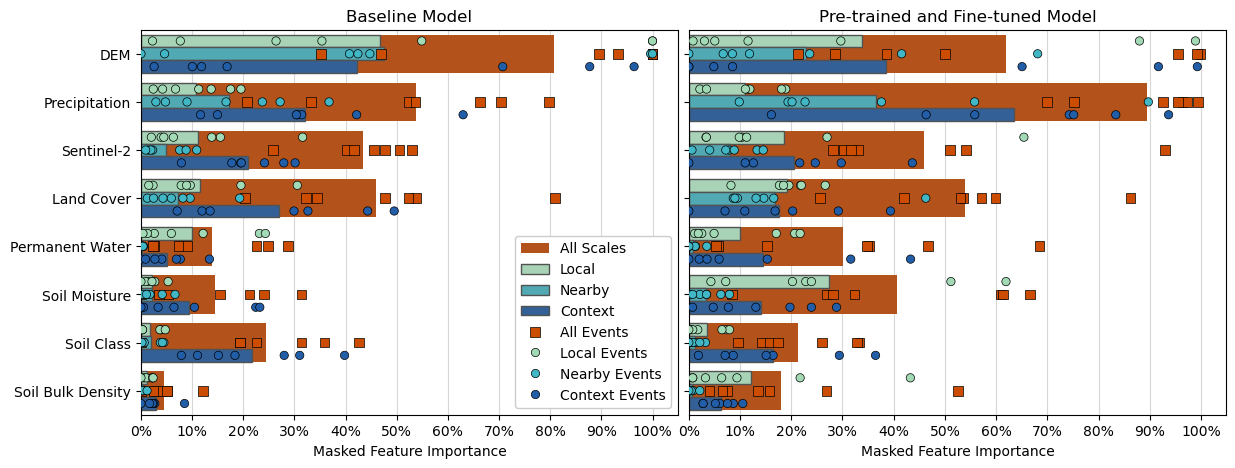

In [2]:
fig = plot_feature_importance(["observational_evalevents_baseline", "observational_finetune_checker_good"], 100, mask_value=0, mask_before_normalization=False, normalise=True, bands=False,
                              config_names=["Baseline Model", "Pre-trained and Fine-tuned Model"])
#fig.savefig("fig_08.png", dpi=300, bbox_inches="tight")

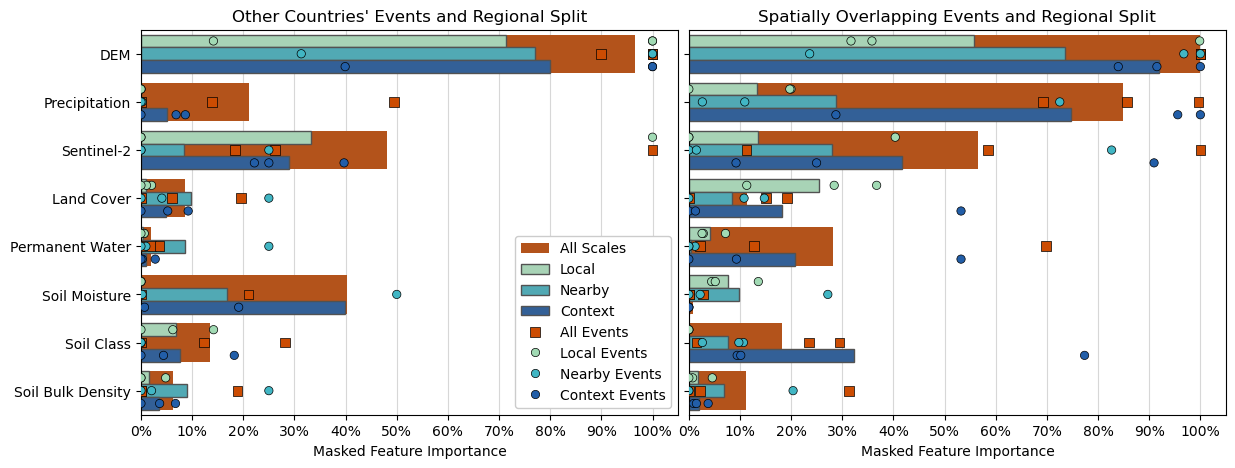

In [3]:
fig = plot_feature_importance(["observational_evalevents_comparison_split", "observational_pretrained_all_overlap_side_split"], 100, mask_value=0, mask_before_normalization=False, normalise=True, bands=False,
                              config_names=["Other Countries' Events and Regional Split", "Spatially Overlapping Events and Regional Split"], only_three=True)
# fig.savefig("fig_13.png", dpi=300, bbox_inches="tight")

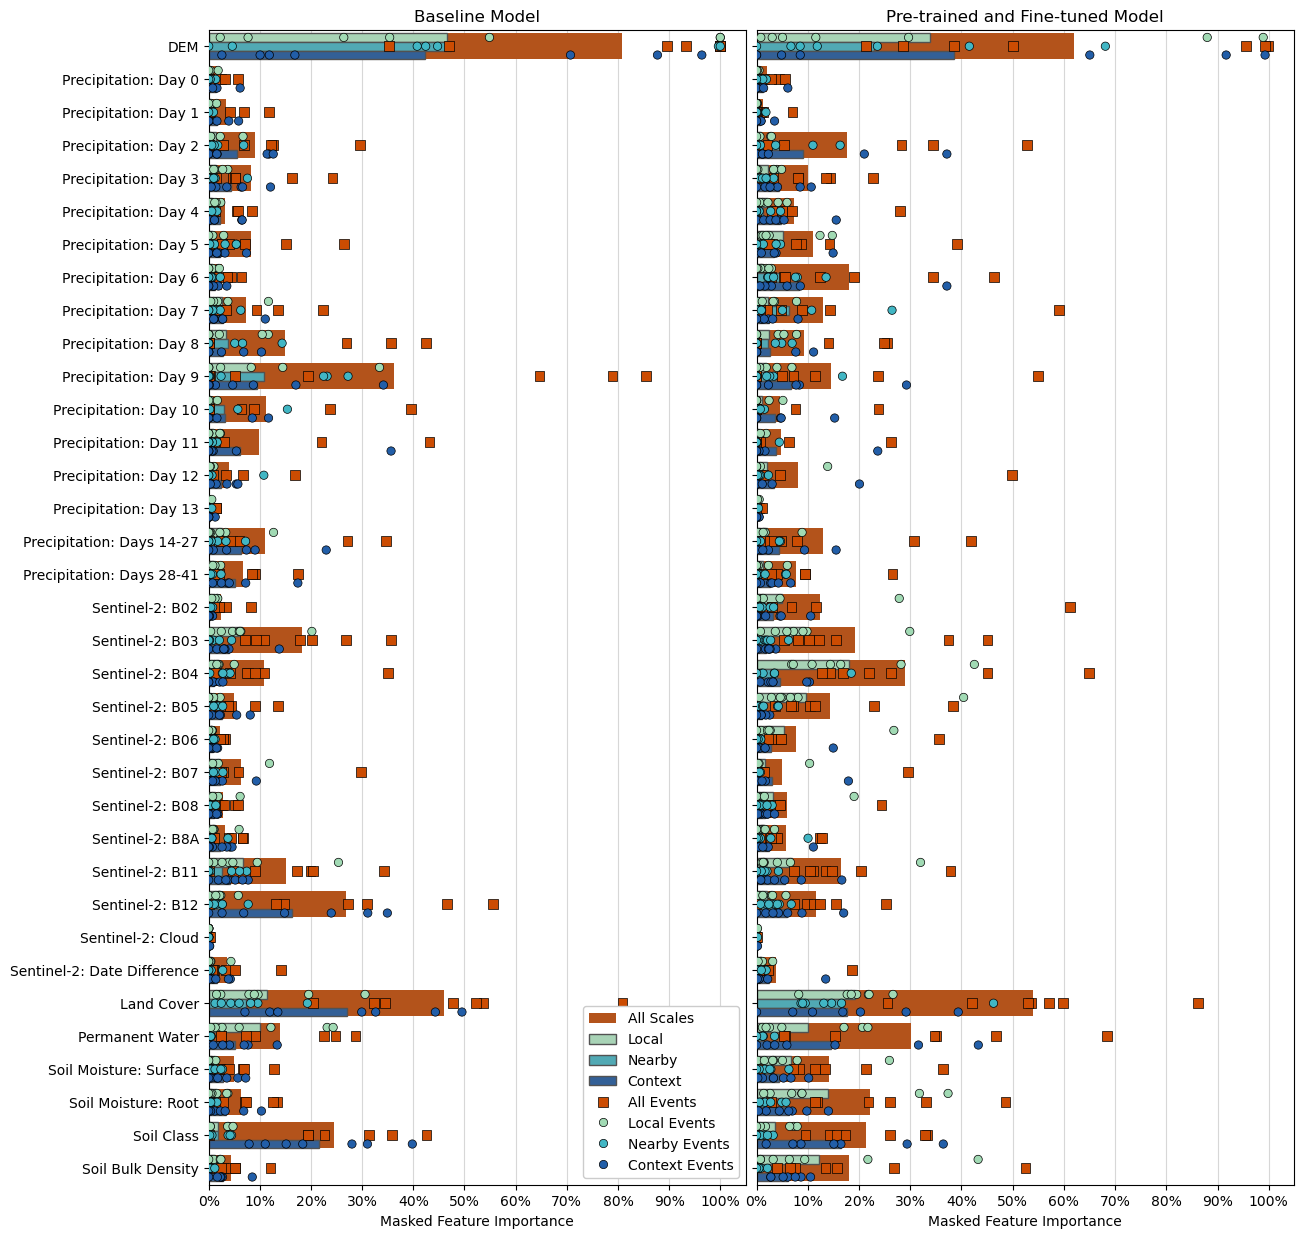

In [4]:
fig = plot_feature_importance(["observational_evalevents_baseline", "observational_finetune_checker_good"], 100, mask_value=0, mask_before_normalization=False, normalise=True, bands=True,
                              config_names=["Baseline Model", "Pre-trained and Fine-tuned Model"])
# fig.savefig("fig_09.png", dpi=300, bbox_inches="tight")

# Feature Distributions by Event

/tmp/ipykernel_1900802/1616197655.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  soil_moist["value"] = soil_moist["value"]/10000


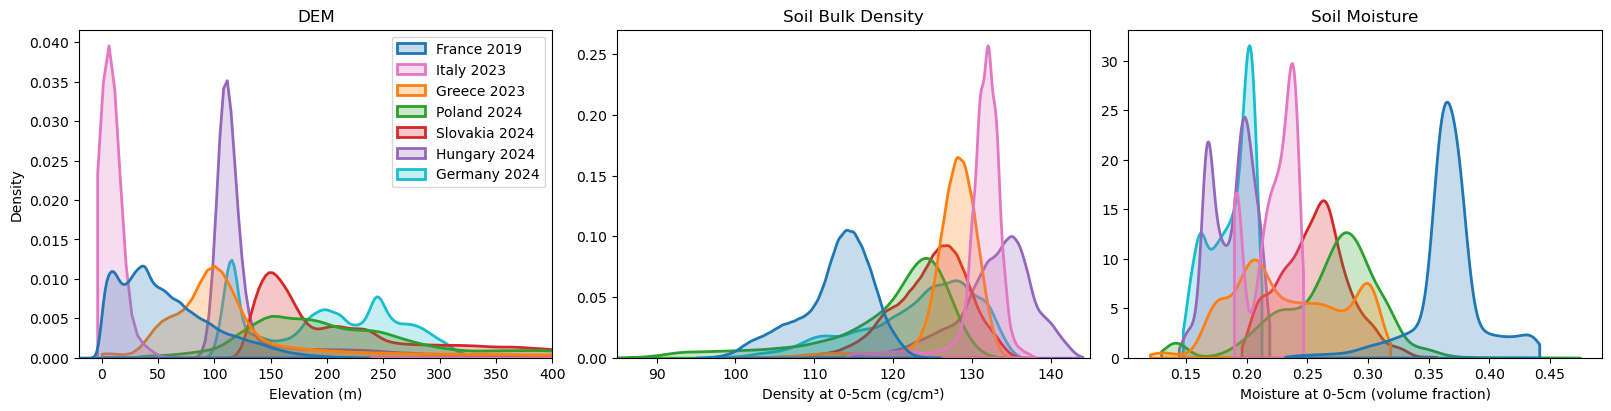

In [5]:
eval_dist = pd.read_csv("/mnt/datadisk2/natasha_flood/dataset/metadata/dataset_distributions_evalevents_subevent_local.csv")
eval_dist = eval_dist[eval_dist["event"].isin(["EMSR759_2024-09-21", "EMSR761_2024-09-19", "EMSR659_2023-05-05", "EMSR416_2019-12-15", "EMSR692_2023-09-10", "EMSR757_2024-09-18", "EMSR756_2024-09-18"])].reset_index(drop=True)
eval_dist = eval_dist.replace({"EMSR759_2024-09-21":"Hungary 2024",
                                "EMSR761_2024-09-19":"Germany 2024",
                                "EMSR659_2023-05-05":"Italy 2023",
                                "EMSR416_2019-12-15":"France 2019",               
                                "EMSR692_2023-09-10":"Greece 2023",
                                "EMSR757_2024-09-18":"Slovakia 2024",
                                "EMSR756_2024-09-18":"Poland 2024"})
eval_dist.loc[-1] = [1000, 15000, "dem_0", "Italy 2023"]

cmap=["#1f77b4","#e377c2", "#ff7f0e", "#2ca02c","#d62728","#9467bd", "#17becf", ]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4), constrained_layout=True)

dem = eval_dist[eval_dist["feature"]=="dem_0"]
soil_moist = eval_dist[eval_dist["feature"]=="soil_moisture_one_day_0"]
soil_moist["value"] = soil_moist["value"]/10000
sbd = eval_dist[eval_dist["feature"]=="soil_bulk_density_0"]

sns.kdeplot(data=dem, x="value", weights="count", hue="event", palette=cmap, fill=True, bw_adjust=0.2, linewidth=2, common_norm=False, cut=0, ax=axes[0])
sns.kdeplot(data=sbd, x="value", weights="count", hue="event", palette=cmap, fill=True, bw_adjust=0.2, linewidth=2, common_norm=False, cut=0, ax=axes[1])
sns.kdeplot(data=soil_moist, x="value", weights="count", hue="event", palette=cmap, fill=True, bw_adjust=0.8, linewidth=2, common_norm=False, cut=0, ax=axes[2])

axes[0].set_xlim([-20, 400]), axes[1].set_xlim([85, 145]), #axes[2].set_xlim([0.11, 0.45])
axes[0].set_xlabel("Elevation (m)"), axes[1].set_xlabel("Density at 0-5cm (cg/cm³)"), axes[2].set_xlabel("Moisture at 0-5cm (volume fraction)"), 
axes[1].set_ylabel(""), axes[2].set_ylabel(""), 
axes[1].get_legend().remove(), axes[2].get_legend().remove()
axes[0].legend_.set_title(None)
axes[0].set_title("DEM"), axes[1].set_title("Soil Bulk Density"), axes[2].set_title("Soil Moisture");

# fig.savefig("feature_distributions.png", dpi=300, bbox_inches="tight")